In [ ]:
import numpy as np
import pandas as pd
import torch # requires pytorch library

### Load speech data

In [ ]:
from pathlib import Path
import os
dir_name = Path("./miller-speeches")
all_speeches = os.listdir(dir_name)
search_string = "Barack_Obama" # search for barck obama in file names
data_files = [f for f in all_speeches if search_string in f]


In [3]:
data_files[:4]

['Barack_Obama_2011-09-08T02:00:00-04:00_September_8,_2011:_Address_to_Congress_on_the_American_Jobs_Act.json',
 'Barack_Obama_2011-10-21T02:00:00-04:00_October_21,_2011:_Remarks_on_the_End_of_the_War_in_Iraq.json',
 'Barack_Obama_2011-05-19T02:00:00-04:00_May_19,_2011:_Speech_on_American_Diplomacy_in_the_Middle_East_and_North_Africa.json',
 'Barack_Obama_2010-08-31T02:00:00-04:00_August_31,_2010:_Address_on_the_End_of_the_Combat_Mission_in_Iraq.json']

In [ ]:
import json
all_chars = []
for data_name in data_files:
    file_name = dir_name / data_name
    with open(file_name, 'r', encoding='utf-8') as file:
        data = json.load(file)
    chars = data['transcript_html']
    all_chars.extend(chars)

In [5]:
len(all_chars)

1296482

In [6]:
np.__version__

'2.5.4'

In [7]:
vocab, indices = np.unique(all_chars, sorted=True, return_inverse=True)
len(vocab)

94

In [9]:
# vocab = sorted(list(set(all_chars)))

In [88]:
# Dataset Params
seq_len = 1000
data_tokens = indices
num_samples = int(len(data_tokens)/seq_len)

In [89]:
random_indices = np.random.permutation(indices)
random_data_tokens = random_indices

In [90]:
import torch
from torch.utils.data import Dataset, DataLoader
# make dataset: batch X seq_len
class SpeechDataset(Dataset):
    def __init__(self, data_tokens, seq_len, vocab, num_samples):
        self.data_tokens = data_tokens
        self.vocab = vocab
        self.seq_len = seq_len
        self.num_samples = num_samples
        
    def __len__(self):
        return self.num_samples
        
    def __getitem__(self, idx):
        
        x = self.data_tokens[idx*seq_len:(idx+1)*seq_len]
        return x

In [102]:
speech_dataset = SpeechDataset(random_data_tokens, seq_len, vocab, num_samples)
data_loader = DataLoader(
    dataset=speech_dataset,
    batch_size=16,
    shuffle=True
)

In [114]:
speech_dataset.data_tokens

array([71,  2, 75, ..., 68, 70, 64], shape=(1296482,))

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
# Create the RNN model class
class RNN(nn.Module):
    def __init__(self, vocab_size, hidden_size, alpha=1):
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding_size = hidden_size
        self.hidden_size = hidden_size
        self.h2h = nn.Linear(hidden_size, hidden_size, bias=True)
        self.h2out = nn.Linear(hidden_size, vocab_size, bias=True)
        self.embedding = nn.Embedding(vocab_size, hidden_size)

        self.alpha = alpha
    def recurrence(self, inputs, hidden):
        h_out = F.tanh(self.h2h(hidden) + self.embedding(inputs))
        h_out = (1-self.alpha)*hidden + self.alpha*h_out
        return h_out
    def forward(self, inputs, h=None): # inputs: (batch, seq)
        batch_size = inputs.shape[0] 
        if not h:
            h=torch.zeros(batch_size, self.hidden_size)
        output_h = []
        steps = range(inputs.size(1))
        for t in steps:
            h=self.recurrence(inputs[:,t], h)
            output_h.append(h)
        # print(output_h[0].shape)
        output_h = torch.stack(output_h, dim=1)
        # print(output_h.shape)
        output_logit = self.h2out(output_h)
        # print(output_logit.shape)

        return output_logit, output_h


In [ ]:
import numpy as np
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# print(device)
model = RNN(vocab_size = len(vocab), hidden_size=1000) # create a model with hidden size
model_untrained = RNN(vocab_size = len(vocab), hidden_size=250)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0)
criterion = nn.CrossEntropyLoss(reduction="mean")
def loss_fn(loss_inputs, loss_targets, l1_lambda=1e-4, model_l1=model):
    loss = criterion(loss_inputs, loss_targets)
    # weight_tensor = model_l1.h2h.weight 
    # loss = loss + l1_lambda * weight_tensor.abs().sum()
    return loss


In [ ]:
import math
# with torch.no_grad():
#     max_weight = model.h2h.weight.cpu().abs().max().numpy()
def update_mask(ex_model, mask):
    with torch.no_grad():
        weights = ex_model.h2h.weight
        weights = mask * weights
        candidate_mask = (weights.abs() < 0.05) & (weights.abs() > 1e-8) # get the weights to remove
        random_values = torch.rand(candidate_mask.shape)
        to_remove = candidate_mask & (random_values < 0.5) # with probability p remove (sparsify) the candidates
        num_removed = to_remove.sum()
        new_mask = mask & (~to_remove) # 0-out to_remove
        num_added = 0
        n = weights.numel()
        # print(num_removed)
        for _ in range(num_removed*10):
            rand_idx = torch.randint(0, n, ()).item()
            if new_mask.contiguous().view(-1)[rand_idx] == 0: # if it's missing a link, add one
                new_mask.contiguous().view(-1)[rand_idx] = 1
                num_added+=1
            if num_added >= num_removed: # exit if we've added as many as we've removed
                break
    return new_mask
def custom_init(ex_model): # erdos renyi
    # scale = 2*(1.0 / math.sqrt(ex_model.h2h.weight.size(1)))
    # scale = 0.5* 1
    with torch.no_grad():
        weights = ex_model.h2h.weight
        random_values = torch.rand(weights.shape)
        mask_p = random_values < 0.8 # 80 percent sparse
        new_weights = torch.where(mask_p, 0, weights)
        # new_weights = torch.where(mask_p, 0, scale*(torch.rand(weights.shape)-0.5))
        ex_model.h2h.weight.copy_(new_weights)

def get_avg_degree(ex_model):
    with torch.no_grad(): 
        weights = ex_model.h2h.weight
        # in_degree = weights.abs().sum(0).item().detach().cpu().numpy()
        # out_degree = weights.abs().sum(1).item().detach().cpu().numpy()
        avg_degree = weights.abs().mean().item()
    return avg_degree

def get_sparsity(ex_model):
    cutoff = 0.03
    with torch.no_grad(): 
        weights = ex_model.h2h.weight
        sparsity = (weights.abs() < cutoff).sum()/weights.numel()
    return sparsity

get_avg_degree(model), get_sparsity(model)

(0.012899348512291908, tensor(1.))

## Training loop

In [ ]:
import time
import numpy as np
from tqdm import tqdm, trange
from pathlib import Path
NUM_EPOCHS = 10
epoch=0 # set to where you are now

loss_over_epochs = np.array([])
loss_over_batches = np.array([])
avg_degree_over_epochs = np.array([])
avg_sparsity_over_epochs = np.array([])
masks_over_updates = []
weights_over_updates = []

# This is not necessary: for masking weights
# with torch.no_grad(): 
#     mask = torch.randn(model.h2h.weight.shape) < 0.3 # start with erdos renyi graph # mask==1 means link exists
# #     # mask = torch.vstack([torch.concatenate((torch.tensor(True).repeat(100), torch.tensor(False).repeat(model.h2h.weight.size(0)-100))).roll(idx) for idx in range(model.h2h.weight.size(0))]).T # strogatz lattice
# #     # # enforce mask
# #     # weights = model.h2h.weight
# #     # new_weights = torch.where(mask, weights, 0)
# #     # model.h2h.weight.copy_(new_weights)


for _ in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    total_sparsity = 0
    total_degree = 0

    t = time.time()
    num_batches = 0
    optimizer.zero_grad()
    with tqdm(data_loader) as pbar:
        for batch_idx, inputs in enumerate(pbar):
            optimizer.zero_grad()

            # with torch.no_grad(): # enforce mask
            #     weights = model.h2h.weight
            #     new_weights = torch.where(mask, weights, 0)
            #     model.h2h.weight.copy_(new_weights)
                
            # For Cross entropy loss
            outputs, hiddens = model(inputs)
            loss_inputs = outputs[..., :-1,:]
            loss_inputs = loss_inputs.permute(0, 2, 1)

            loss_targets = inputs[..., 1:]
            loss = loss_fn(loss_inputs, loss_targets) # expects inputs: (N, C, d1, d2, ...), targets: (N, d1, d2, ...)
            loss.backward()
            # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            # with torch.no_grad(): # make grad update proportional to degree (preferential attachment)
            #     # degs = (model.h2h.weight.abs().sum(0) + model.h2h.weight.abs().sum(1))
            #     degs = (mask.sum(0) + mask.sum(1))
            #     degs = degs.reshape(1, -1)
            #     if (degs.max() - degs.min()) > 0.001: # for numerical stability
            #         degs = 1e-0*(degs - degs.min())/ (degs.max() - degs.min()) # rescale lr*(0 to 1)
            #         grads_multiplier = (degs.T @ degs)
            #         model.h2h.weight.grad.copy_(model.h2h.weight.grad * grads_multiplier)
            
            optimizer.step()
            total_loss = total_loss + loss.item()
            sparsity = get_sparsity(model)
            # sparsity = ((~mask).sum())/mask.numel()
            avg_degree = get_avg_degree(model)
            # avg_degree = mask.sum(0).float().std().item() # actually 2nd moment
            total_sparsity += sparsity
            total_degree += avg_degree

            loss_over_batches = np.append(loss_over_batches, loss.item())
            if batch_idx % 30 == 0:
                pbar.set_postfix(Epoch=epoch+1, Batch=batch_idx, loss=f'{loss.item():.4f}', sparsity=sparsity, degree=avg_degree)
                # if epoch >= 2:
                #     enforce_constraints(model) # enforce weight constraints

                # mask = update_mask(model, mask)
                # masks_over_updates.append(mask)
                weights_over_updates.append(model.h2h.weight.detach().cpu().numpy().copy())

            #     # optimizer.step()
            #     # optimizer.zero_grad()
            #     print(f'Epoch {epoch+1} | Batch {batch_idx} | Loss: {loss.item():.4f}')
            num_batches += 1

    loss_over_epochs = np.append(loss_over_epochs, total_loss/num_batches)
    avg_degree_over_epochs = np.append(avg_degree_over_epochs, total_degree/num_batches)
    avg_sparsity_over_epochs = np.append(avg_sparsity_over_epochs, total_sparsity/num_batches)
    print(f'Epoch {epoch+1} | Avg Loss: {total_loss/num_batches:.4f} | Time: {time.time()-t:.2f}')

    epoch += 1




100%|██████████| 81/81 [03:20<00:00,  2.47s/it, Batch=60, Epoch=1, degree=18.8, loss=3.2021, sparsity=tensor(0.3828)]


Epoch 1 | Avg Loss: 3.2516 | Time: 200.36


100%|██████████| 81/81 [03:20<00:00,  2.47s/it, Batch=60, Epoch=2, degree=18.8, loss=3.1982, sparsity=tensor(0.3828)]


Epoch 2 | Avg Loss: 3.1938 | Time: 200.39


100%|██████████| 81/81 [03:15<00:00,  2.41s/it, Batch=60, Epoch=3, degree=18.8, loss=3.1827, sparsity=tensor(0.3828)]


...

Epoch 8 | Avg Loss: 3.1639 | Time: 163.34


100%|██████████| 81/81 [02:45<00:00,  2.04s/it, Batch=60, Epoch=9, degree=18.8, loss=3.1653, sparsity=tensor(0.3828)]


Epoch 9 | Avg Loss: 3.1563 | Time: 165.50


100%|██████████| 81/81 [02:50<00:00,  2.10s/it, Batch=60, Epoch=10, degree=18.8, loss=3.1651, sparsity=tensor(0.3828)]

Epoch 10 | Avg Loss: 3.1467 | Time: 170.14


In [ ]:
# Save/load model
# np.savez('./save_out/random_model_epochs.npz', loss_over_epochs=loss_over_epochs,loss_over_batches=loss_over_batches,
#     mask=mask, weights_over_updates=weights_over_updates, masks_over_updates=masks_over_updates)
#
# with np.load('./save_out/model_epochs.npz') as data:
#     locals().update(data)

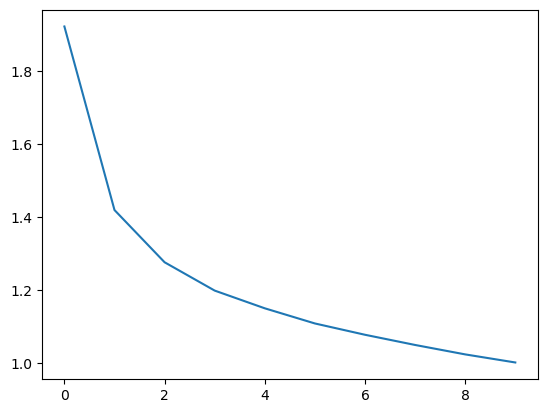

In [100]:
import matplotlib.pyplot as plt
plt.plot(loss_over_epochs)
# plt.plot(avg_sparsity_over_epochs)
# plt.plot(avg_degree_over_epochs)

In [ ]:
# Generate output (characters) with the trained model

In [1176]:
#
steps_to_gen = 250
seed_input = torch.tensor(np.arange(40, 80).reshape(-1, 1))
p = 0.3
with torch.no_grad():
    for _ in trange(steps_to_gen):
        last_input = seed_input[:, :]
        outputs, hiddens = model(last_input)
        temperature = 1.0
        outputs = outputs[:, [-1], :]
        logits = outputs / temperature
        probs = torch.softmax(logits, dim=-1)[:,-1]
        sorted_probs, sorted_indices = torch.sort(probs, dim=-1, descending=True)
        sorted_probs = sorted_probs
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)
        sorted_indices_to_remove = cumulative_probs - sorted_probs > p # shift over by one before removing
        sorted_probs[sorted_indices_to_remove] = 0.0
        sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
        sampled_sorted_idx = torch.multinomial(sorted_probs, num_samples=1)
        # # Map the sampled indices from the sorted tensor back to original vocabulary IDs
        gen_out = torch.gather(sorted_indices, dim=-1, index=sampled_sorted_idx)
        
        seed_input = torch.concatenate([seed_input, gen_out], dim=-1)
        



100%|██████████| 250/250 [00:05<00:00, 44.23it/s]


In [ ]:
seed_idx = 29
vocab[seed_input][seed_idx,:] # visualize output


array(['m', 'i', 'n', 'g', ' ', 't', 'h', 'e', ' ', 's', 'u', 'r', 'e',
       ' ', 't', 'h', 'e', ' ', 'c', 'o', 'm', 'p', 'a', 'n', 'i', 't',
       'i', 'o', 'n', 's', ' ', 'o', 'f', ' ', 't', 'h', 'e', ' ', 's',
       't', 'a', 'n', 'd', ' ', 't', 'h', 'e', ' ', 'c', 'o', 'm', 'm',
       'u', 'n', 'i', 't', 'y', ' ', 't', 'o', ' ', 't', 'h', 'e', ' ',
       's', 'u', 'r', 'e', ' ', 't', 'h', 'e', ' ', 's', 'u', 'r', 'e',
       ' ', 't', 'h', 'e', ' ', 's', 't', 'r', 'e', 'e', 'd', ' ', 't',
       'h', 'e', ' ', 'p', 'r', 'o', 't', 'e', 'd', ' ', 't', 'h', 'e',
       ' ', 'w', 'i', 'l', 'l', ' ', 'b', 'e', ' ', 'a', 'n', 'd', ' ',
       't', 'h', 'e', ' ', 'w', 'o', 'r', 'l', 'd', ' ', 't', 'h', 'e',
       ' ', 'w', 'o', 'r', 'l', 'd', ' ', 't', 'h', 'e', ' ', 's', 't',
       'r', 'e', 'n', 't', 'i', 'o', 'n', 's', ' ', 'a', 'n', 'd', ' ',
       't', 'h', 'e', ' ', 'c', 'o', 'm', 'p', 'a', 'n', 'c', 'e', ' ',
       't', 'h', 'e', ' ', 's', 't', 'r', 'e', 'n', 't', 's', ' 

## Get degree statistics and ouptut to Gephi

In [39]:
h2h_detached = np.abs(model.h2h.weight.cpu().detach().numpy())
h2h_detached_untrained = np.abs(model_untrained.h2h.weight.cpu().detach().numpy())

# threshold = 1/math.sqrt(model.h2h.weight.size(0))
threshold = 0.03
h2h_detached_thresh = np.abs(h2h_detached) > threshold
h2h_detached_untrained_thresh = np.abs(h2h_detached_untrained) > threshold

# h2h_detached_thresh = masks_over_updates[-1].int().cpu().detach().numpy()

In [1250]:
(np.abs(h2h_detached) <= 0.001).sum()

np.int64(41989)

In [43]:
# in_degree = np.sum(h2h_detached, axis=0)
# out_degree = np.sum(h2h_detached, axis=1)
# in_degree_null = np.sum(h2h_detached_untrained, axis=0)
# out_degree_null = np.sum(h2h_detached_untrained, axis=1)

in_degree = np.sum(h2h_detached_thresh, axis=0)
out_degree = np.sum(h2h_detached_thresh, axis=1)
in_degree_null = np.sum(h2h_detached_untrained_thresh, axis=0)
out_degree_null = np.sum(h2h_detached_untrained_thresh, axis=1)

In [116]:
# weights_over_updates[0], weights_over_updates[1]

Text(0.5, 1.0, 'Obama Speeches')

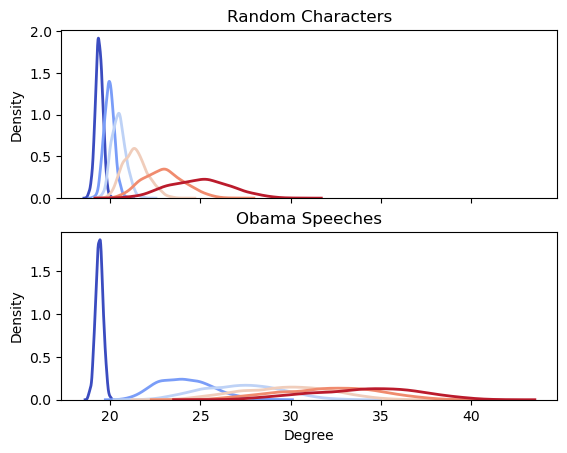

In [130]:
import seaborn as sns

cmap = plt.cm.coolwarm
with np.load('./save_out/random_model_epochs.npz') as data:
    locals().update(data)

fig, ax = plt.subplots(2, 1, sharex=True)

for i in range(len(weights_over_updates)):
    if i%5==0:
        h2h_detached_thresh = weights_over_updates[i]
        avg_degree = 0.5*(np.sum(np.abs(h2h_detached_thresh), axis=1) + np.sum(np.abs(h2h_detached_thresh), axis=0))
        # plt.hist(avg_degree, color=cmap(i*10), alpha=0.8) 
        # sns.kdeplot(avg_degree, ax=ax[0], fill=False, color="grey",alpha=0.5, linewidth=2)
        sns.kdeplot(avg_degree, ax=ax[0], fill=False, color=cmap(i*10), linewidth=2)

ax[0].set_title('Random Characters')

with np.load('./save_out/model_epochs.npz') as data:
    locals().update(data)

for i in range(len(weights_over_updates)):
    if i%5==0:
        h2h_detached_thresh = weights_over_updates[i]
        avg_degree = 0.5*(np.sum(np.abs(h2h_detached_thresh), axis=1) + np.sum(np.abs(h2h_detached_thresh), axis=0))
        # plt.hist(avg_degree, color=cmap(i*10), alpha=0.8) 
        sns.kdeplot(avg_degree, ax=ax[1], fill=False, color=cmap(i*10), linewidth=2)
ax[1].set_xlabel('Degree')
ax[1].set_title('Obama Speeches')

# for i in range(len(masks_over_updates)):
#     if i%5==0:
#         h2h_detached_thresh = masks_over_updates[i].int().cpu().detach().numpy()
#         avg_degree = 0.5*(np.sum(h2h_detached_thresh, axis=1) + np.sum(h2h_detached_thresh, axis=0))
#         # plt.hist(avg_degree, color=cmap(i*10), alpha=0.8) 
#         sns.kdeplot(avg_degree, fill=False, color=cmap(i*10), linewidth=2)



(array([19., 48., 50., 54., 37., 24., 27., 17., 18.,  6.]),
 array([134. , 147.5, 161. , 174.5, 188. , 201.5, 215. , 228.5, 242. ,
        255.5, 269. ]),
 <BarContainer object of 10 artists>)

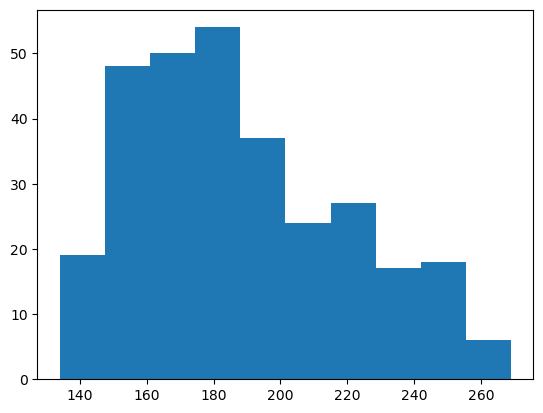

In [44]:
plt.hist(out_degree + in_degree) 

(array([18., 19., 50., 51., 74., 30., 39.,  9.,  8.,  2.]),
 array([24. , 26.5, 29. , 31.5, 34. , 36.5, 39. , 41.5, 44. , 46.5, 49. ]),
 <BarContainer object of 10 artists>)

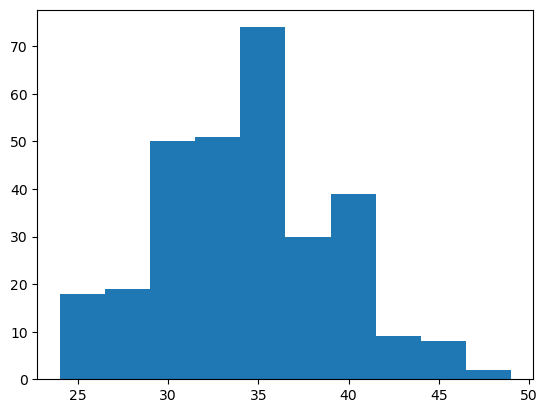

In [1191]:
plt.hist(out_degree) 
# plt.hist(out_degree_null)

# plt.hist(in_degree)


(array([56203., 55971., 55698., 56356., 56251., 56447., 55974., 56405.,
        56275., 56920.]),
 array([8.70581562e-09, 3.65148857e-03, 7.30296876e-03, 1.09544480e-02,
        1.46059282e-02, 1.82574093e-02, 2.19088886e-02, 2.55603697e-02,
        2.92118490e-02, 3.28633264e-02, 3.65148075e-02]),
 <BarContainer object of 10 artists>)

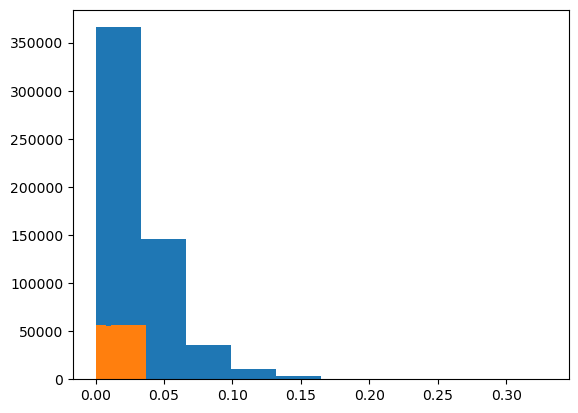

In [993]:
plt.hist(h2h_detached.flatten())
plt.hist(h2h_detached_untrained.flatten())

In [51]:
# Save for giphy
import numpy as np
import pandas as pd

# Example: Assume 'adj_matrix' is a 2D numpy array or pandas DataFrame
# and 'node_labels' is a list of node names/IDs

# adj_matrix = np.abs(h2h_detached)
adj_matrix = h2h_detached_thresh
node_labels = np.arange(len(adj_matrix))

# df_adj = pd.DataFrame(adj_matrix, index=node_labels, columns=node_labels)

# Convert adjacency matrix to edge list
edges = []
nodes = node_labels

for i in range(len(node_labels)):
    for j in range(len(node_labels)):
        weight = adj_matrix[i, j]
        # if i>=j:# get triangle only
        #     continue
        if weight != 0:  # Skip non-existent edges
            edges.append({
                'Source': node_labels[i],
                'Target': node_labels[j],
                'Type': 'Directed',  # Change to 'Directed' if needed
                'Weight': weight
            })

df_edges = pd.DataFrame(edges)
df_nodes = pd.DataFrame({'Id': list(nodes), 'Label': list(nodes)})

# Save to CSV files for Gephi
df_nodes.to_csv('nodes.csv', index=False)
df_edges.to_csv('edges.csv', index=False)
